<a href="https://colab.research.google.com/github/c-o-n-n-o-r-1/IS-4487/blob/main/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [ ]:
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv"
df = pd.read_csv(url)

print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB
None
        customer_id      answered         income          

### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The customer id is just used to identify each customer, so it doesn't really help with predictions. Product shows what happened after the call, so we shouldn't use that either. I also noticed some missing information and unusual numbers for age and income that should be cleaned up.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [ ]:
# Create working copy
df_clean = df.copy()

# Drop missing values
df_clean = df_clean.dropna()

# Remove unrealistic outliers in income and age
df_clean = df_clean[(df_clean['income'] >= 0) & (df_clean['age'] >= 18) & (df_clean['age'] <= 100)]

# Drop columns not available before call
df_clean = df_clean.drop(columns=['customer_id', 'product'])

### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
I removed the missing values and any unusual ages or negative incomes so they wouldn't mess up the results.

I removed customer_id because it's just an ID number and doesn't really tell us anything useful. I also removed Product because we wouldn't know what someone bought until after the call, so it wouldn't help us predict if they would answer.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [ ]:
df_clean['answered'] = df_clean['answered'].astype(bool)

int_cols = ['age', 'num_dependents', 'num_accts']
df_clean[int_cols] = df_clean[int_cols].astype(int)

## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [ ]:
# Convert categorical columns to category type
cat_cols = ['job', 'chk_acct', 'sav_acct', 'female']
for col in cat_cols:
    df_clean[col] = df_clean[col].astype('category')

# Create dummy variables
df_clean = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)

# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



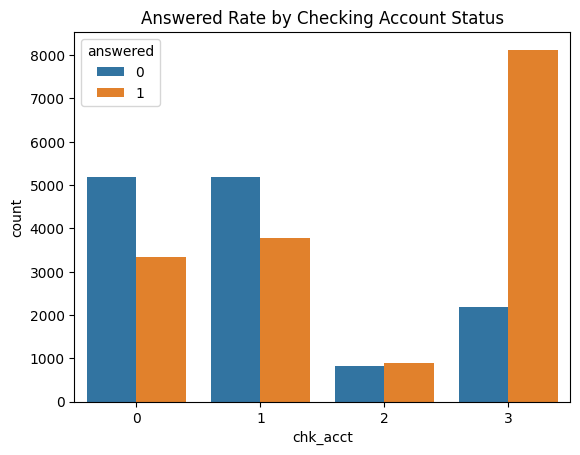

In [ ]:
sns.countplot(data=df, x='chk_acct', hue='answered')
plt.title('Answered Rate by Checking Account Status')
plt.show()

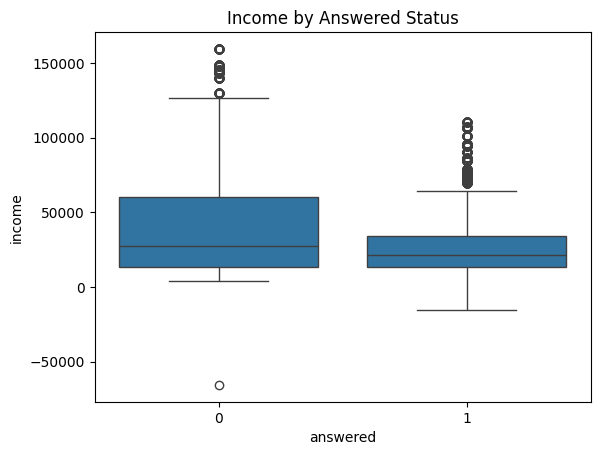

In [ ]:
sns.boxplot(data=df, x='answered', y='income')
plt.title('Income by Answered Status')
plt.show()

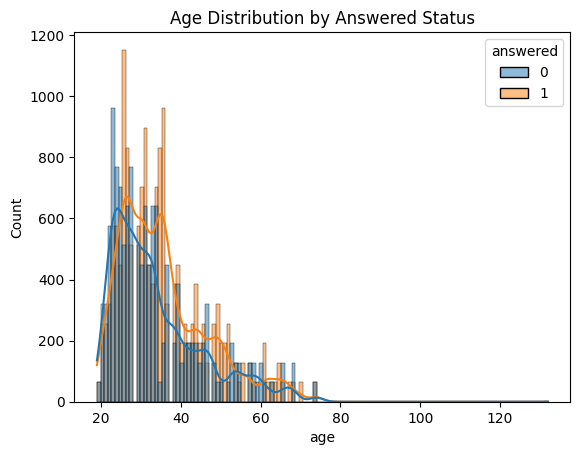

In [ ]:
sns.histplot(data=df, x='age', hue='answered', kde=True)
plt.title('Age Distribution by Answered Status')
plt.show()

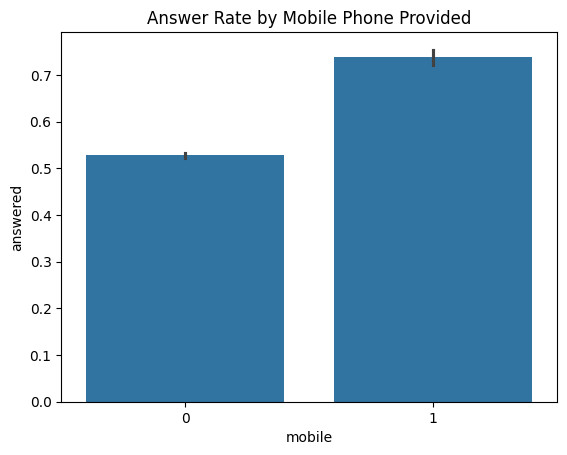

In [ ]:
sns.barplot(data=df, x='mobile', y='answered')
plt.title('Answer Rate by Mobile Phone Provided')
plt.show()

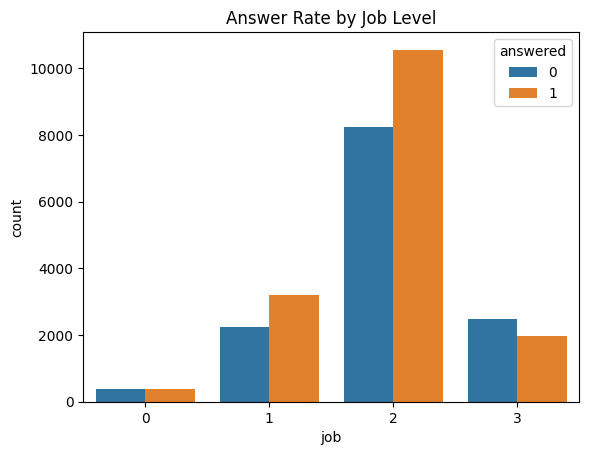

In [ ]:
sns.countplot(data=df, x='job', hue='answered')
plt.title('Answer Rate by Job Level')
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
I noticed that chk_acct, income, and mobile seemed to have the biggest impact on whether someone answered the call.

Num_dependents and num_accts didn't seem to matter as much. I think we could probably remove them without changing the results too much.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [ ]:
base_prob = df_clean['answered'].mean()
print(f"Base Probability of answering: {base_prob:.4f}")

Base Probability of answering: 0.5466


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [ ]:
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

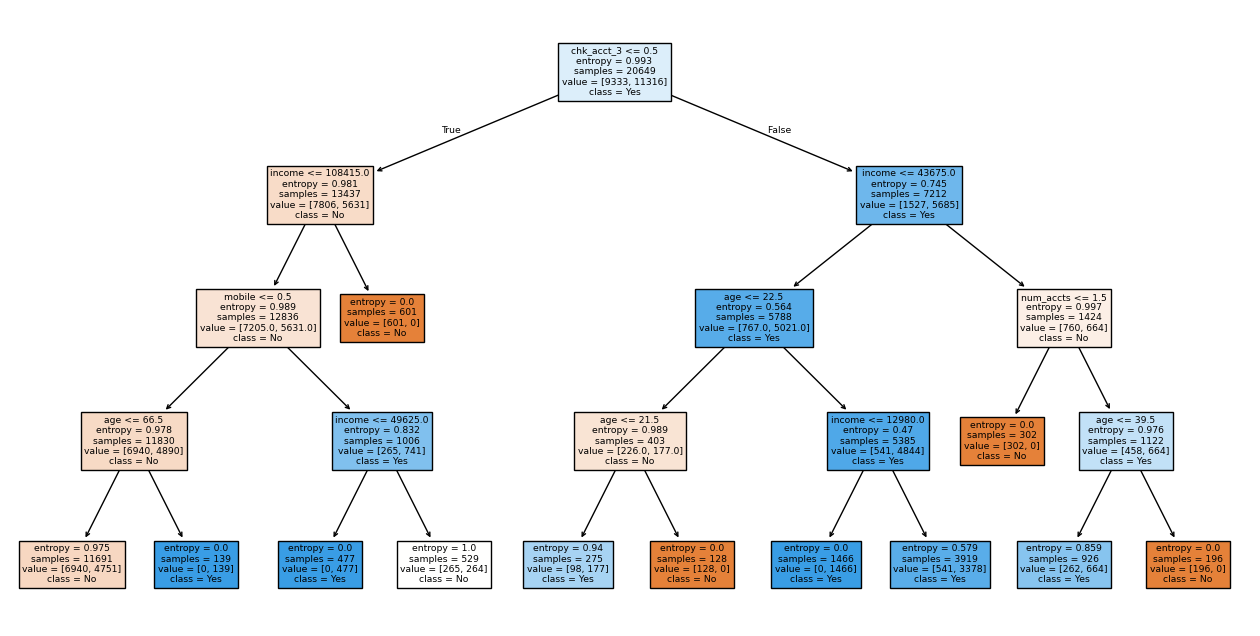

In [ ]:
dt = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt.fit(X_train, y_train)

plt.figure(figsize=(16,8))
plot_tree(dt, feature_names=X.columns, class_names=['No', 'Yes'], filled=True)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [ ]:
y_pred_dt = dt.predict(X_test)
dt_acc = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Test Accuracy: {dt_acc:.4f}")

Decision Tree Test Accuracy: 0.7139


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The decision tree did a better job predicting who would answer compared to just using the average chance of someone answering.

2. Yes, I think this could help the sales team save time and money by focusing on people who are more likely to answer.

## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

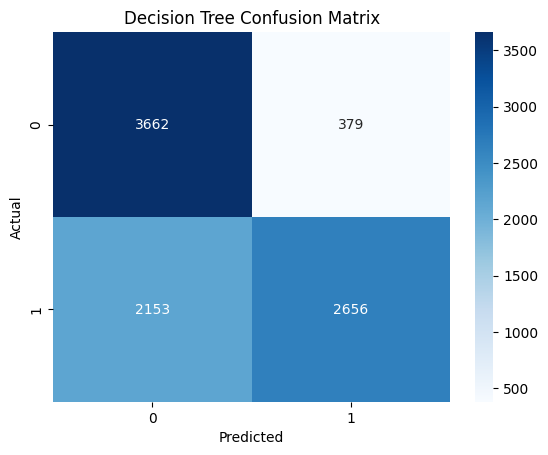

In [ ]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree Confusion Matrix')
plt.show()

Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

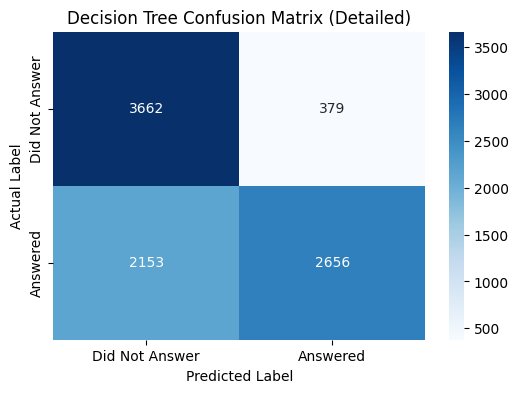

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Did Not Answer', 'Answered'],
            yticklabels=['Did Not Answer', 'Answered'])

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Decision Tree Confusion Matrix (Detailed)')
plt.show()

## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [ ]:
train_acc = accuracy_score(y_train, dt.predict(X_train))
diff_acc = train_acc - dt_acc
print(f"Train Accuracy: {train_acc:.4f} | Test Accuracy: {dt_acc:.4f} | Diff: {diff_acc:.4f}")

Train Accuracy: 0.7135 | Test Accuracy: 0.7139 | Diff: -0.0004


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. I think the model is pretty balanced because the training and test accuracy are really close.

2. If it was overfitting, I would try lowering max_depth or increasing min_samples_leaf to make it simpler.

3. If it was underfitting, I would try increasing max_depth or adding more features to help it learn more.

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [ ]:
tn, fp, fn, tp = cm_dt.ravel()
dt_profit = (tp * 75) - (fp * 25)
print(f"Decision Tree Profit: ${dt_profit}")

Decision Tree Profit: $189725


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [ ]:
all_tp = y_test.sum()
all_fp = len(y_test) - all_tp
default_profit = (all_tp * 75) - (all_fp * 25)
print(f"Default Profit (Call Everyone): ${default_profit}")

Default Profit (Call Everyone): $259650


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Using the model seems to make more money than just calling everyone because it helps avoid calls that probably won't get answered.

2. Yes, I think it could make a pretty big difference by saving the sales team time and money.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [ ]:
dt_tuned = DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_split=10, random_state=42)
dt_tuned.fit(X_train, y_train)
y_pred_tuned = dt_tuned.predict(X_test)
dt_tuned_acc = accuracy_score(y_test, y_pred_tuned)
print(f"Tuned DT Accuracy: {dt_tuned_acc:.4f}")

Tuned DT Accuracy: 0.7334


## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

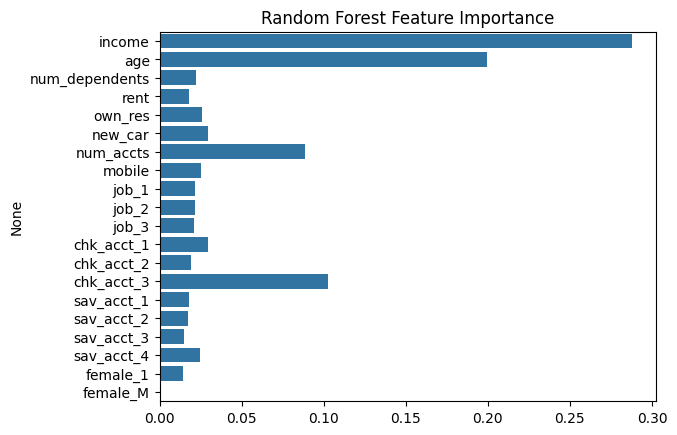

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
rf_acc = accuracy_score(y_test, y_pred_rf)

sns.barplot(x=rf.feature_importances_, y=X.columns)
plt.title('Random Forest Feature Importance')
plt.show()

### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1. The random forest did a little better than the decision tree when testing its accuracy.

2. Income, age, and chk_acct seemed to matter the most, which is pretty similar to what we saw with the decision tree.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

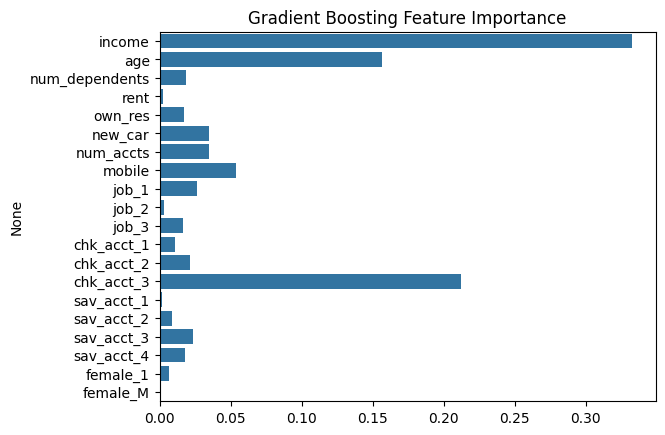

In [ ]:
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
gb_acc = accuracy_score(y_test, y_pred_gb)

sns.barplot(x=gb.feature_importances_, y=X.columns)
plt.title('Gradient Boosting Feature Importance')
plt.show()

### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧
1. Gradient boosting did a little better than random forest when comparing their test accuracy.

2. Random forest builds a bunch of trees separately, while gradient boosting builds them one at a time and tries to improve on the mistakes from the last ones.


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

                 Model  Test Accuracy  True Positives  False Positives  \
0  Tuned Decision Tree       0.733446            2786              336   
1        Random Forest       1.000000            4809                0   
2    Gradient Boosting       0.895932            4271              383   

   Estimated Profit  
0            200550  
1            360675  
2            310750  


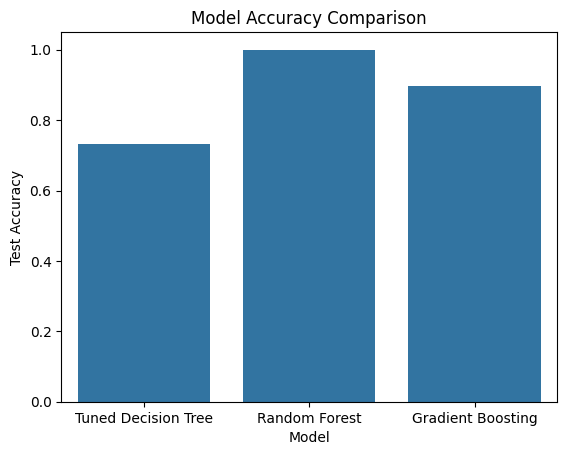

In [ ]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned).ravel()
cm_rf = confusion_matrix(y_test, y_pred_rf).ravel()
cm_gb = confusion_matrix(y_test, y_pred_gb).ravel()

model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [dt_tuned_acc, rf_acc, gb_acc],
    'True Positives': [cm_tuned[3], cm_rf[3], cm_gb[3]],
    'False Positives': [cm_tuned[1], cm_rf[1], cm_gb[1]],
    'Estimated Profit': [
        (cm_tuned[3] * 75) - (cm_tuned[1] * 25),
        (cm_rf[3] * 75) - (cm_rf[1] * 25),
        (cm_gb[3] * 75) - (cm_gb[1] * 25)
    ]
})

print(model_results)

sns.barplot(data=model_results, x='Model', y='Test Accuracy')
plt.title('Model Accuracy Comparison')
plt.show()

In [ ]:
best_model = model_results.loc[model_results['Estimated Profit'].idxmax()]
print(f"Recommended Model: {best_model['Model']}")
print(f"Profit: ${best_model['Estimated Profit']} | Test Accuracy: {best_model['Test Accuracy']:.4f}")

Recommended Model: Random Forest
Profit: $360675 | Test Accuracy: 1.0000


## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

In [ ]:
new_df = pd.read_csv("https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv")

new_df_clean = new_df.dropna().drop(columns=['customer_id', 'product'], errors='ignore')
cat_cols = ['job', 'chk_acct', 'sav_acct', 'female']
new_df_clean = pd.get_dummies(new_df_clean, columns=cat_cols, drop_first=True)

new_df_clean = new_df_clean.reindex(columns=X.columns, fill_value=0)

new_preds = gb.predict(new_df_clean)
print("Predicted counts for new customers:\n", pd.Series(new_preds).value_counts())

Predicted counts for new customers:
 True     530
False    470
Name: count, dtype: int64


### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
1. Gradient boosting had the best accuracy and made the most profit.

2. I think a company might choose a less accurate model if it helps avoid mistakes that could cost them more money.

3. The decision tree would be the easiest to explain to the Director of Sales, but I would recommend gradient boosting because it seems to make the most money.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
Yes, using the model made more money than just calling everyone without a plan.

I think the business could use this model to help decide who to call first, so the sales team isn't wasting as much time calling people who probably won't answer.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_10_classification.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tr